# Daily Challenge - Statistics for Machine Learning

**What is in this notebook**

- **Part 1 – Applying Inferential Statistics:** I complete every TODO and question of the course template (t-tests and bootstrapping on the bank churn data).
- **Part 2 – Predicting churn with machine learning (scikit-learn):** I build, train and evaluate classification models that predict which customers will leave the bank: handling missing values, encoding the categorical features, a train/test split, Logistic Regression, Random Forest and Gradient Boosting, accuracy / precision / recall / F1, a confusion matrix, and what the results mean for the bank's business decisions.

Both parts use the same course dataset, `Churn_Modelling.csv` (from `Inferential Statistics.zip`).

## How to run in Colab
1. I open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** and choose this file.
2. I keep the course dataset zip **`Inferential Statistics.zip`** in my `C:\Users\sivan\Datasets` folder (I don't unzip it myself).
3. I run the cells from top to bottom. When the upload cell opens a file picker, I choose `Inferential Statistics.zip`. The next line unzips it and gives me **`Churn_Modelling.csv`**.

The template says to load the CSV from a Kaggle link. That Kaggle notebook uses the bank churn file `Churn_Modelling.csv`, which is exactly the file inside the course zip, so I use the zip.

(If I run the notebook on my own computer instead of Colab, the upload step is skipped and the zip just needs to be in the same folder as the notebook.)

In [1]:
try:
    from google.colab import files
    uploaded = files.upload()  # Prompts user to select zip file
except ImportError:
    print("Not running in Colab: I use the zip that is already next to this notebook.")
!unzip -o "Inferential Statistics.zip"     # Unzips uploaded dataset file

Not running in Colab: I use the zip that is already next to this notebook.
Archive:  Inferential Statistics.zip
  inflating: Churn_Modelling.csv     


# Part 1 – Applying Inferential Statistics (course template)

# Applying Inferential Statistics

### Here are the hypotheses to test:
1. Age of people who left the bank and who did not are similar. Alternative: Not similar.
2. Credit score of people who left the bank and who did not are similar. Alternative: Not similar.
3. Balance of people who left the bank and who did not are similar. Alternative: Not similar.
4. Estimated Salary of people who left the bank and who did not are similar. Alternative: Not similar.

#### The most appropriate test to analyse data here is Frequentist test.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import scipy.stats
from scipy.stats import t
from scipy.special import stdtr
from numpy.random import seed
import seaborn as sns

%matplotlib inline
from matplotlib import rcParams
sns.set_style("whitegrid")
sns.set_context("poster")

In [3]:
matplotlib.rcParams['figure.figsize'] = (8.0, 5.0)

In [4]:
## TODO : load the csv file from this link : https://www.kaggle.com/code/vaibhagarwal/inferential-statistics/input
# The input of that Kaggle notebook is the bank churn file "Churn_Modelling.csv".
# The course gives me the same file inside "Inferential Statistics.zip", which I unzipped at the top of this notebook.
file_1 = pd.read_csv('Churn_Modelling.csv')

In [5]:
## TODO : make into a dataframe called df
df = pd.DataFrame(file_1)
print(f"Shape: {df.shape}")
print(f"Missing values in the whole table: {df.isnull().sum().sum()}")

Shape: (10000, 14)
Missing values in the whole table: 0


In [6]:
## TODO : output the first 5 lines
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [7]:
## TODO : Create two separate DataFrames, `df_0` and `df_1`, to filter customers who have not exited (0) and customers who have exited (1), respectively
df_0 = df[df['Exited'] == 0]   # customers who stayed with the bank
df_1 = df[df['Exited'] == 1]   # customers who left the bank (churned)
print(f"Stayed (df_0): {len(df_0)} customers")
print(f"Left   (df_1): {len(df_1)} customers")
print(f"Churn rate: {len(df_1) / len(df):.1%}")

Stayed (df_0): 7963 customers
Left   (df_1): 2037 customers
Churn rate: 20.4%


## Hypothesis 1: Age

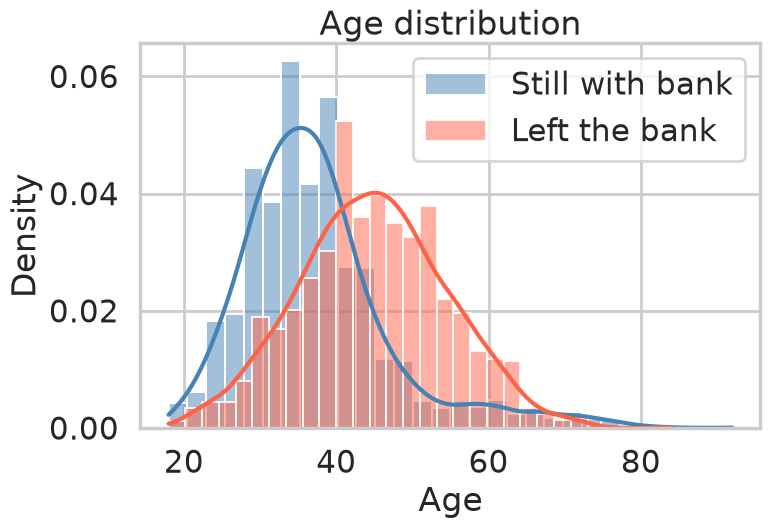

In [8]:
## TODO: Plot the age distribution for customers who stayed with the bank and those who left using seaborn, with different colors for each group and a legend.
sns.histplot(df_0['Age'], color='steelblue', label='Still with bank', kde=True, stat='density', bins=30, alpha=0.5)
sns.histplot(df_1['Age'], color='tomato', label='Left the bank', kde=True, stat='density', bins=30, alpha=0.5)
plt.title('Age distribution')
plt.xlabel('Age')
plt.legend()
plt.show()

In [9]:
## TODO: Calculate the mean and standard deviation of the age for customers who stayed with the bank.
age_mean_stayed = df_0['Age'].mean()
age_std_stayed = df_0['Age'].std()
print(f"Stayed: mean age = {age_mean_stayed:.2f}, standard deviation = {age_std_stayed:.2f}")

Stayed: mean age = 37.41, standard deviation = 10.13


In [10]:
## TODO: Calculate the mean and standard deviation of the age for customers who left the bank.
age_mean_left = df_1['Age'].mean()
age_std_left = df_1['Age'].std()
print(f"Left:   mean age = {age_mean_left:.2f}, standard deviation = {age_std_left:.2f}")

Left:   mean age = 44.84, standard deviation = 9.76


In [11]:
## TODO: Perform a t-test to compare the ages of customers who stayed and left the bank.
# H0: the mean age of stayers and leavers is the same. H1: the mean ages are different (two-sided).
# The two groups have very different sizes (7963 vs 2037), so I use Welch's t-test (equal_var=False),
# which does not assume that both groups have the same variance.
t_stat_age, p_value_age = scipy.stats.ttest_ind(df_0['Age'], df_1['Age'], equal_var=False)
print(f"t-statistic = {t_stat_age:.3f}")
print(f"p-value     = {p_value_age:.3e}")
print("Reject H0" if p_value_age < 0.05 else "Fail to reject H0", "at alpha = 0.05")

t-statistic = -30.419
p-value     = 4.713e-179
Reject H0 at alpha = 0.05


### Using Bootstrapping

In [12]:
## TODO: Write a function to perform bootstrap sampling and calculate the statistic of interest.
def bs_choice(data, func, size):
    bs_s = np.empty(size)                                   # an empty array to store one result per resample
    for i in range(size):
        bs_abc = np.random.choice(data, size=len(data))     # resample WITH replacement, same size as the data
        bs_s[i] = func(bs_abc)                              # compute the statistic (e.g. the mean) on the resample
    return bs_s

In [13]:
## TODO: Calculate the difference in means and shift the ages to the overall mean.
# Observed difference (left - stayed):
age_observed_diff = df_1['Age'].mean() - df_0['Age'].mean()
print(f"Observed difference in mean age (left - stayed): {age_observed_diff:.3f} years")

# To simulate "H0 is true", I move both groups so that they have the same mean (the overall mean),
# but keep their own shape and spread.
age_overall_mean = df['Age'].mean()
age_shifted_stayed = df_0['Age'] - df_0['Age'].mean() + age_overall_mean
age_shifted_left = df_1['Age'] - df_1['Age'].mean() + age_overall_mean
print(f"Overall mean age: {age_overall_mean:.3f}")
print(f"Shifted means: stayed = {age_shifted_stayed.mean():.3f}, left = {age_shifted_left.mean():.3f}")

Observed difference in mean age (left - stayed): 7.430 years
Overall mean age: 38.922
Shifted means: stayed = 38.922, left = 38.922


In [14]:
## TODO: Perform bootstrap sampling to calculate the standard deviation for both groups and their difference.
seed(47)                       # so I get the same random resamples every time I run the notebook
number_of_resamples = 10000

# Bootstrap means of the shifted groups (= what the means look like when H0 is true)
bs_age_means_stayed = bs_choice(age_shifted_stayed, np.mean, number_of_resamples)
bs_age_means_left = bs_choice(age_shifted_left, np.mean, number_of_resamples)
bs_age_diff = bs_age_means_left - bs_age_means_stayed

# The standard deviation of these bootstrap means is the standard error of each mean
print(f"Bootstrap std of the mean age, stayed: {bs_age_means_stayed.std():.4f}")
print(f"Bootstrap std of the mean age, left:   {bs_age_means_left.std():.4f}")
print(f"Bootstrap std of the difference:       {bs_age_diff.std():.4f}")

# The (unshifted) standard deviation of age in each group, also with bootstrapping:
bs_age_std_stayed = bs_choice(df_0['Age'], np.std, 1000)
bs_age_std_left = bs_choice(df_1['Age'], np.std, 1000)
print(f"Bootstrap mean of the age standard deviation: stayed = {bs_age_std_stayed.mean():.3f}, left = {bs_age_std_left.mean():.3f}")

Bootstrap std of the mean age, stayed: 0.1125
Bootstrap std of the mean age, left:   0.2158
Bootstrap std of the difference:       0.2433
Bootstrap mean of the age standard deviation: stayed = 10.131, left = 9.754


Observed difference: 7.430 years
Largest absolute difference in 10000 bootstrap samples under H0: 0.950 years
Bootstrap p-value = 0.0
(None of the 10000 resamples was that extreme, so p < 0.0001)


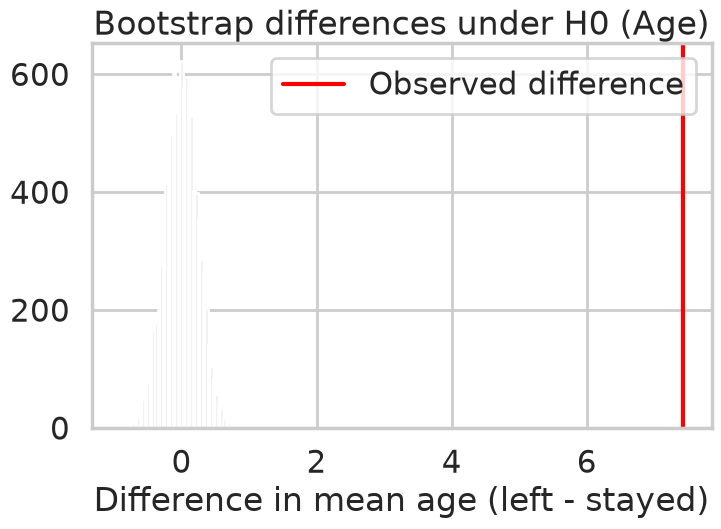

In [15]:
## TODO: Calculate the p-value by comparing the difference in means to the bootstrap distribution.
# Two-sided p-value: how often is a difference under H0 at least as big (in absolute value) as the one I observed?
p_value_age_bs = np.sum(np.abs(bs_age_diff) >= np.abs(age_observed_diff)) / len(bs_age_diff)
print(f"Observed difference: {age_observed_diff:.3f} years")
print(f"Largest absolute difference in {number_of_resamples} bootstrap samples under H0: {np.abs(bs_age_diff).max():.3f} years")
print(f"Bootstrap p-value = {p_value_age_bs}")
if p_value_age_bs == 0:
    print(f"(None of the {number_of_resamples} resamples was that extreme, so p < {1 / number_of_resamples})")

plt.hist(bs_age_diff, bins=50, color='grey')
plt.axvline(age_observed_diff, color='red', label='Observed difference')
plt.title('Bootstrap differences under H0 (Age)')
plt.xlabel('Difference in mean age (left - stayed)')
plt.legend()
plt.show()

### Conclusion
Do we reject the Null Hypothesis ? Why ?

**My answer:** Yes, I reject the null hypothesis. Customers who left are older on average (44.84 years) than customers who stayed (37.41 years), a difference of 7.43 years. Welch's t-test gives t = -30.42 and p ≈ 4.7e-179, far below 0.05. The bootstrap agrees: when I simulate "no difference" 10,000 times, the biggest difference I ever get is 0.95 years, never close to 7.43, so the bootstrap p-value is 0.0 (smaller than 1/10,000). Age is clearly related to churn.

## Hypothesis 2: Credit Score

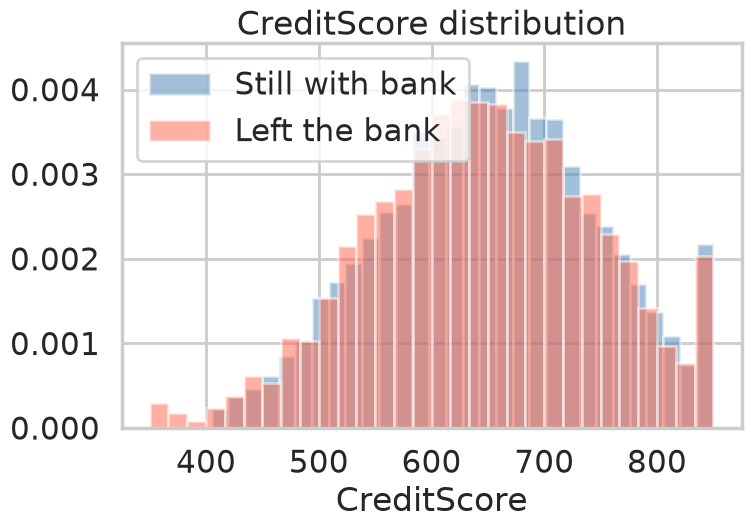

Mean CreditScore: stayed = 651.85, left = 645.35


In [16]:
## TODO: Create histograms for the CreditScore distribution of both groups (Still with bank and Left the bank).
plt.hist(df_0['CreditScore'], bins=30, alpha=0.5, density=True, color='steelblue', label='Still with bank')
plt.hist(df_1['CreditScore'], bins=30, alpha=0.5, density=True, color='tomato', label='Left the bank')
plt.title('CreditScore distribution')
plt.xlabel('CreditScore')
plt.legend()
plt.show()
print(f"Mean CreditScore: stayed = {df_0['CreditScore'].mean():.2f}, left = {df_1['CreditScore'].mean():.2f}")

In [17]:
## TODO: Perform a t-test to compare the CreditScore between the two groups (Still with bank and Left the bank).
t_stat_credit, p_value_credit = scipy.stats.ttest_ind(df_0['CreditScore'], df_1['CreditScore'], equal_var=False)
print(f"t-statistic = {t_stat_credit:.3f}")
print(f"p-value     = {p_value_credit:.4f}")
print("Reject H0" if p_value_credit < 0.05 else "Fail to reject H0", "at alpha = 0.05")

t-statistic = 2.635
p-value     = 0.0085
Reject H0 at alpha = 0.05


### Conclusion
Do we reject the Null Hypothesis ? Why ?

**My answer:** Yes, I reject the null hypothesis at α = 0.05, but only just. Welch's t-test gives t = 2.63 and p = 0.0085 < 0.05. Leavers have a slightly lower mean credit score (645.35 vs 651.85, only about 6.5 points). The two histograms almost completely overlap, so the difference is statistically significant (thanks to 10,000 customers), but it is very small in practice. Credit score alone would not separate leavers from stayers well.

## Hypothesis 3: Balance

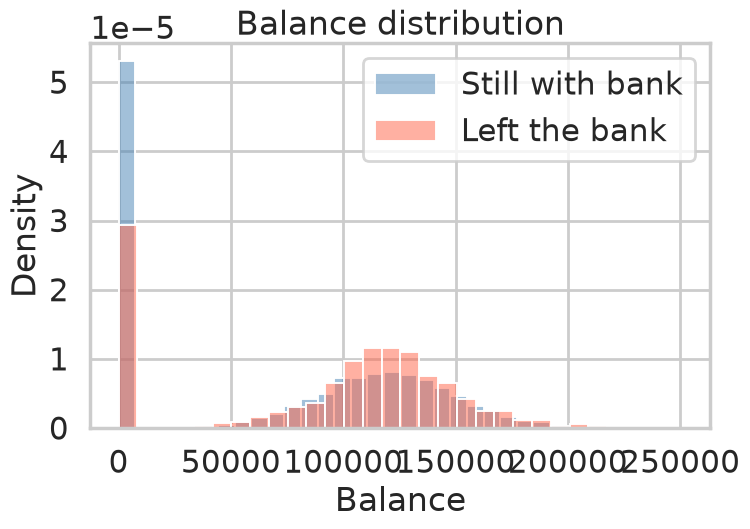

Mean Balance: stayed = 72,745.30, left = 91,108.54
Share of customers with a balance of exactly 0: stayed = 39.1%, left = 24.5%


In [18]:
## TODO: Plot the distribution of Balance for both groups (Still with bank and Left the bank).
sns.histplot(df_0['Balance'], color='steelblue', label='Still with bank', stat='density', bins=30, alpha=0.5)
sns.histplot(df_1['Balance'], color='tomato', label='Left the bank', stat='density', bins=30, alpha=0.5)
plt.title('Balance distribution')
plt.xlabel('Balance')
plt.legend()
plt.show()
print(f"Mean Balance: stayed = {df_0['Balance'].mean():,.2f}, left = {df_1['Balance'].mean():,.2f}")
print(f"Share of customers with a balance of exactly 0: stayed = {(df_0['Balance'] == 0).mean():.1%}, left = {(df_1['Balance'] == 0).mean():.1%}")

In [19]:
## TODO: Perform a t-test to compare the Balance between customers who stayed with the bank and those who left.
t_stat_balance, p_value_balance = scipy.stats.ttest_ind(df_0['Balance'], df_1['Balance'], equal_var=False)
print(f"t-statistic = {t_stat_balance:.3f}")
print(f"p-value     = {p_value_balance:.3e}")
print("Reject H0" if p_value_balance < 0.05 else "Fail to reject H0", "at alpha = 0.05")

t-statistic = -12.471
p-value     = 6.319e-35
Reject H0 at alpha = 0.05


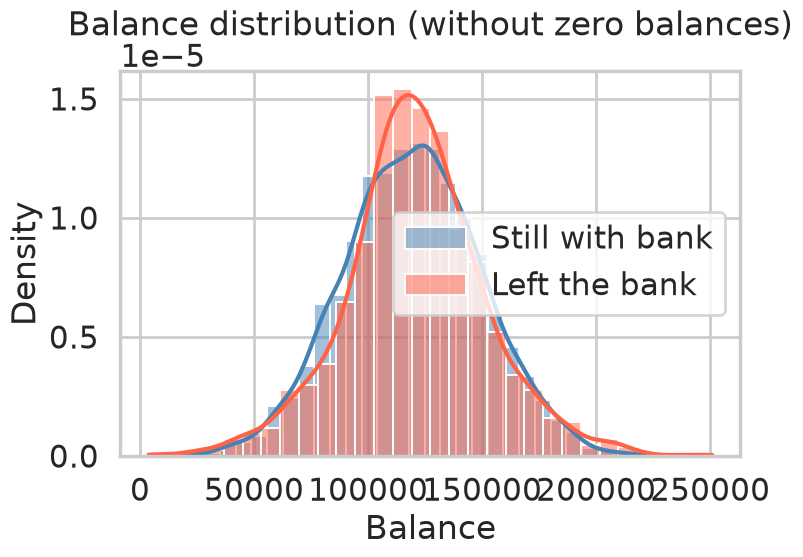

Customers with balance > 0: stayed = 4846, left = 1537
Mean non-zero Balance: stayed = 119,535.86, left = 120,746.97


In [20]:
## TODO: Visualize the distribution of Balance for customers who stayed with the bank and those who left, excluding zero balances.
balance_nonzero_stayed = df_0.loc[df_0['Balance'] > 0, 'Balance']
balance_nonzero_left = df_1.loc[df_1['Balance'] > 0, 'Balance']
sns.histplot(balance_nonzero_stayed, color='steelblue', label='Still with bank', kde=True, stat='density', bins=30, alpha=0.5)
sns.histplot(balance_nonzero_left, color='tomato', label='Left the bank', kde=True, stat='density', bins=30, alpha=0.5)
plt.title('Balance distribution (without zero balances)')
plt.xlabel('Balance')
plt.legend()
plt.show()
print(f"Customers with balance > 0: stayed = {len(balance_nonzero_stayed)}, left = {len(balance_nonzero_left)}")
print(f"Mean non-zero Balance: stayed = {balance_nonzero_stayed.mean():,.2f}, left = {balance_nonzero_left.mean():,.2f}")

In [21]:
## TODO: Perform a t-test to compare the Balance between customers who stayed with the bank and those who left, excluding zero balances.
t_stat_balance_nz, p_value_balance_nz = scipy.stats.ttest_ind(balance_nonzero_stayed, balance_nonzero_left, equal_var=False)
print(f"t-statistic = {t_stat_balance_nz:.3f}")
print(f"p-value     = {p_value_balance_nz:.4f}")
print("Reject H0" if p_value_balance_nz < 0.05 else "Fail to reject H0", "at alpha = 0.05")

t-statistic = -1.360
p-value     = 0.1738
Fail to reject H0 at alpha = 0.05


## Conclusion

Do we reject the Null Hypothesis ? Why ?

**My answer:** It depends on which test I look at, and that tells me something useful.
- **All customers:** I reject H0. Leavers have a higher mean balance (91,108.54 vs 72,745.30); t = -12.47, p ≈ 6.3e-35.
- **Without zero balances:** I fail to reject H0. Among customers who have money in the account, the means are almost the same (120,746.97 vs 119,535.86); t = -1.36, p = 0.174 > 0.05.

So the difference comes from the **share of zero balances**: 39.1% of stayers have a balance of exactly 0, against only 24.5% of leavers. The zeros pull the stayers' mean down. Having money in the account (balance > 0) is linked to churn, but *how much* money is not.

## Hypothesis 4: Estimated Salary

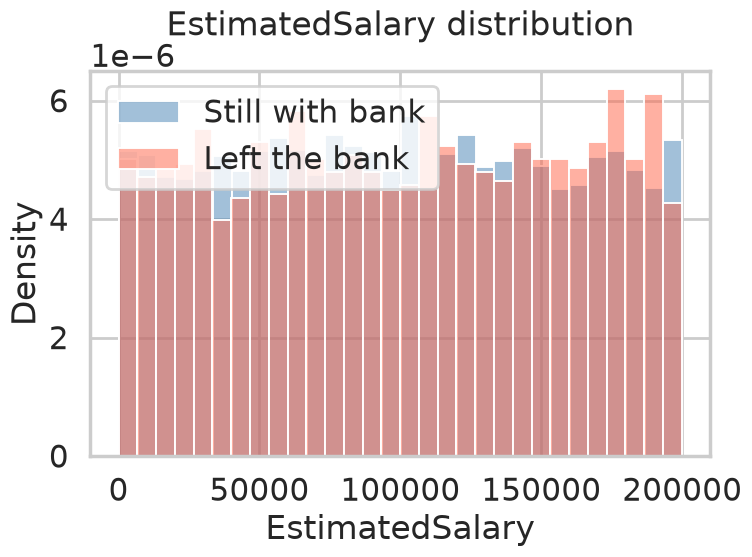

Mean EstimatedSalary: stayed = 99,738.39, left = 101,465.68


In [22]:
## TODO: Plot the distribution of EstimatedSalary for customers who stayed with the bank and those who left.
sns.histplot(df_0['EstimatedSalary'], color='steelblue', label='Still with bank', stat='density', bins=30, alpha=0.5)
sns.histplot(df_1['EstimatedSalary'], color='tomato', label='Left the bank', stat='density', bins=30, alpha=0.5)
plt.title('EstimatedSalary distribution')
plt.xlabel('EstimatedSalary')
plt.legend()
plt.show()
print(f"Mean EstimatedSalary: stayed = {df_0['EstimatedSalary'].mean():,.2f}, left = {df_1['EstimatedSalary'].mean():,.2f}")

In [23]:
## TODO: Perform a t-test to compare the EstimatedSalary between customers who stayed and those who left.
t_stat_salary, p_value_salary = scipy.stats.ttest_ind(df_0['EstimatedSalary'], df_1['EstimatedSalary'], equal_var=False)
print(f"t-statistic = {t_stat_salary:.3f}")
print(f"p-value     = {p_value_salary:.4f}")
print("Reject H0" if p_value_salary < 0.05 else "Fail to reject H0", "at alpha = 0.05")

t-statistic = -1.203
p-value     = 0.2289
Fail to reject H0 at alpha = 0.05


### Using Bootstrapping

In [24]:
## TODO: Calculate the difference in means and shift the EstimatedSalary for both groups.
salary_observed_diff = df_1['EstimatedSalary'].mean() - df_0['EstimatedSalary'].mean()
print(f"Observed difference in mean EstimatedSalary (left - stayed): {salary_observed_diff:,.2f}")

salary_overall_mean = df['EstimatedSalary'].mean()
salary_shifted_stayed = df_0['EstimatedSalary'] - df_0['EstimatedSalary'].mean() + salary_overall_mean
salary_shifted_left = df_1['EstimatedSalary'] - df_1['EstimatedSalary'].mean() + salary_overall_mean
print(f"Shifted means: stayed = {salary_shifted_stayed.mean():,.2f}, left = {salary_shifted_left.mean():,.2f}")

Observed difference in mean EstimatedSalary (left - stayed): 1,727.29
Shifted means: stayed = 100,090.24, left = 100,090.24


In [25]:
## TODO: Calculate the bootstrap sample means for both groups and their difference.
seed(47)
bs_salary_means_stayed = bs_choice(salary_shifted_stayed, np.mean, number_of_resamples)
bs_salary_means_left = bs_choice(salary_shifted_left, np.mean, number_of_resamples)
bs_salary_diff = bs_salary_means_left - bs_salary_means_stayed
print(f"Bootstrap std of the difference in means under H0: {bs_salary_diff.std():,.2f}")

Bootstrap std of the difference in means under H0: 1,445.10


Observed difference: 1,727.29
Bootstrap p-value = 0.2317


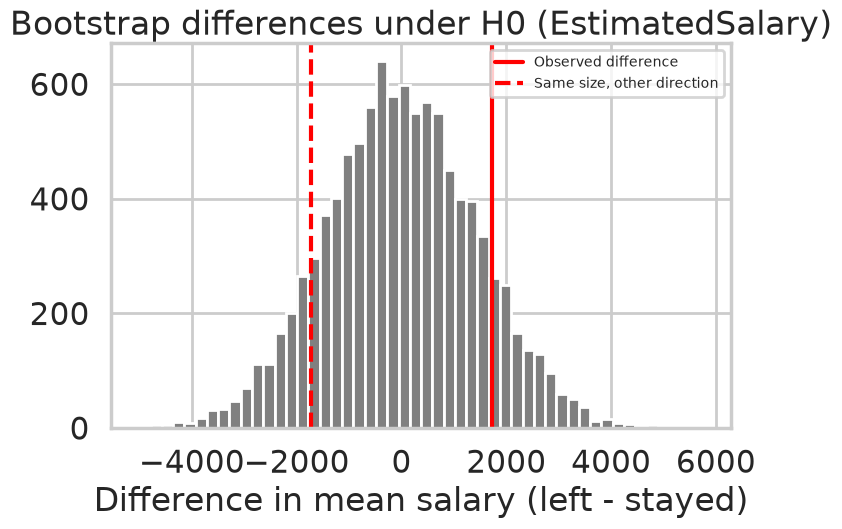

In [26]:
## TODO: Calculate the p-value based on the bootstrap distribution of the difference in means.
p_value_salary_bs = np.sum(np.abs(bs_salary_diff) >= np.abs(salary_observed_diff)) / len(bs_salary_diff)
print(f"Observed difference: {salary_observed_diff:,.2f}")
print(f"Bootstrap p-value = {p_value_salary_bs:.4f}")

plt.hist(bs_salary_diff, bins=50, color='grey')
plt.axvline(salary_observed_diff, color='red', label='Observed difference')
plt.axvline(-salary_observed_diff, color='red', linestyle='--', label='Same size, other direction')
plt.title('Bootstrap differences under H0 (EstimatedSalary)')
plt.xlabel('Difference in mean salary (left - stayed)')
plt.legend(fontsize=10)
plt.show()

### Conclusion
Do we reject the Null Hypothesis ? Why ?

**My answer:** No, I fail to reject the null hypothesis. The mean estimated salary is almost the same for leavers (101,465.68) and stayers (99,738.39), a difference of only 1,727.29. Welch's t-test gives p = 0.229, and the bootstrap test gives p = 0.2317. Both are above 0.05, so the difference could easily be random. Estimated salary does not seem to be related to churn.

## Final Conclusion
What will be the most helpful feature in predicting churning?

**My answer:** **Age** is the most helpful of the four features for predicting churn. It has by far the strongest result (t = -30.42, p ≈ 4.7e-179, and a 7.4-year gap between the groups), and leavers are clearly older. **Balance** comes next, but mainly through whether the balance is zero or not (zero-balance share 39.1% for stayers vs 24.5% for leavers). The amount itself is not significant once the zeros are removed (p = 0.174). **CreditScore** is significant (p = 0.0085) but the gap is tiny (about 6.5 points). **EstimatedSalary** is not significant (p ≈ 0.23). If I build a churn model later, I would start with Age and a "has a balance" (Balance > 0) feature.

# Part 2 – Predicting churn with machine learning (scikit-learn)

In Part 1 I tested features one by one. Now I want a **model** that looks at all the customer information together and predicts if a customer will leave the bank (`Exited = 1`) or stay (`Exited = 0`). This is a **binary classification** problem.

My plan:
1. Prepare the data: drop columns that are only IDs, check and handle missing values, and encode the categorical features.
2. Split the data into a training set and a test set.
3. Train several classifiers with scikit-learn.
4. Evaluate them with accuracy, precision, recall, F1 and a confusion matrix.
5. Interpret the results for the bank.

## Step 1 – Preparing the data

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)

ml_df = df.copy()
# RowNumber, CustomerId and Surname only identify a customer, they don't describe behaviour,
# so a model would only memorise them. I remove them.
ml_df = ml_df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

print("Missing values per column:")
print(ml_df.isnull().sum())
print("\nData types:")
print(ml_df.dtypes)

Missing values per column:
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Data types:
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object


In [28]:
# Target (what I want to predict) and features (what I use to predict it)
y = ml_df['Exited']
X = ml_df.drop(columns=['Exited'])

categorical_features = ['Geography', 'Gender']                      # text columns
numeric_features = [col for col in X.columns if col not in categorical_features]
print("Categorical features:", categorical_features)
print("Numeric features:   ", numeric_features)
print("\nValues of the categorical features:")
for col in categorical_features:
    print(f"  {col}: {X[col].unique().tolist()}")
print(f"\nShare of customers who left (Exited = 1): {y.mean():.1%}")

Categorical features: ['Geography', 'Gender']
Numeric features:    ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']

Values of the categorical features:
  Geography: ['France', 'Spain', 'Germany']
  Gender: ['Female', 'Male']

Share of customers who left (Exited = 1): 20.4%


**My notes on the data:** The dataset has no missing values (every column shows 0). I still put an imputer (`SimpleImputer`) in my preprocessing, so the model would not break if new customer data had empty cells. There are two categorical (text) features, `Geography` (France, Spain, Germany) and `Gender` (Female, Male). A model only understands numbers, so I turn them into 0/1 columns with one-hot encoding. Only 20.4% of customers left, so the classes are imbalanced. I need to keep that in mind when I read the accuracy.

In [29]:
# Preprocessing with a ColumnTransformer:
# - numeric columns: fill missing values with the median, then standardise (mean 0, std 1)
#   so features with big numbers (Balance, EstimatedSalary) don't dominate Logistic Regression
# - categorical columns: fill missing values with the most frequent value, then one-hot encode
#   (Geography -> Geography_France / Geography_Germany / Geography_Spain, Gender -> Gender_Female / Gender_Male)
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features),
])

# Small demo: what the encoded data looks like (fitted here only to show the column names)
demo = preprocessor.fit(X)
print("Columns after preprocessing:", demo.get_feature_names_out().tolist())

Columns after preprocessing: ['num__CreditScore', 'num__Age', 'num__Tenure', 'num__Balance', 'num__NumOfProducts', 'num__HasCrCard', 'num__IsActiveMember', 'num__EstimatedSalary', 'cat__Geography_France', 'cat__Geography_Germany', 'cat__Geography_Spain', 'cat__Gender_Female', 'cat__Gender_Male']


## Step 2 – Train/test split

In [30]:
# 80% of the customers to train the models, 20% kept aside to test them on data they have never seen.
# stratify=y keeps the same share of leavers in both sets; random_state makes the split reproducible.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training set: {X_train.shape[0]} customers, churn rate {y_train.mean():.1%}")
print(f"Test set:     {X_test.shape[0]} customers, churn rate {y_test.mean():.1%}")

# A "dumb" baseline: always predict that nobody leaves
baseline_accuracy = (y_test == 0).mean()
print(f"\nBaseline accuracy if I always predict 'stays': {baseline_accuracy:.3f}")

Training set: 8000 customers, churn rate 20.4%
Test set:     2000 customers, churn rate 20.3%

Baseline accuracy if I always predict 'stays': 0.796


**My note:** Both sets keep about the same churn rate (20.4% train, 20.3% test) thanks to `stratify`. The baseline is important: if I just predict "stays" for everybody, I already get **79.6% accuracy** without catching a single leaver. A useful model must do clearly better than that, and accuracy alone is not enough to judge it.

## Step 3 – Training several classifiers

In [31]:
# Each model is a Pipeline: preprocessing + classifier. The preprocessing is fitted ONLY on the
# training data inside the pipeline, so no information from the test set leaks into training.
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

results = []
fitted_models = {}
for name, classifier in models.items():
    model = Pipeline([('preprocess', preprocessor), ('classifier', classifier)])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    fitted_models[name] = model
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, y_proba),
    })

results_df = pd.DataFrame(results).set_index('Model').round(3)
results_df

,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Logistic Regression,0.808,0.589,0.187,0.284,0.775
Random Forest,0.858,0.759,0.442,0.559,0.849
Gradient Boosting,0.869,0.782,0.494,0.605,0.870


## Step 4 – Evaluating the models

What the metrics mean (class 1 = "left the bank"):
- **Accuracy:** share of all test customers the model classified correctly.
- **Precision:** of the customers the model flagged as "will leave", how many really left.
- **Recall:** of the customers who really left, how many the model caught.
- **F1:** one number that balances precision and recall.
- **ROC AUC:** how well the model ranks leavers above stayers (0.5 = random, 1 = perfect).

**My notes on the results (test set, 2000 customers):**
- **Logistic Regression:** accuracy 0.808, precision 0.589, recall 0.187, F1 0.284. Its accuracy is barely above the 0.796 baseline, and it catches fewer than 1 leaver in 5. A straight-line model is too simple here. For example, churn is low for 2 products but very high for 3 or 4, and it can't capture that.
- **Random Forest:** accuracy 0.858, precision 0.759, recall 0.442, F1 0.559.
- **Gradient Boosting:** accuracy 0.869, precision 0.782, recall 0.494, F1 0.605, ROC AUC 0.870. **This is my best model.** It has the highest score on every metric.

The two tree models are much better than Logistic Regression because they can learn non-linear patterns and combinations of features.

Best model by F1: Gradient Boosting

              precision    recall  f1-score   support

  Stayed (0)       0.88      0.96      0.92      1593
    Left (1)       0.78      0.49      0.61       407

    accuracy                           0.87      2000
   macro avg       0.83      0.73      0.76      2000
weighted avg       0.86      0.87      0.86      2000



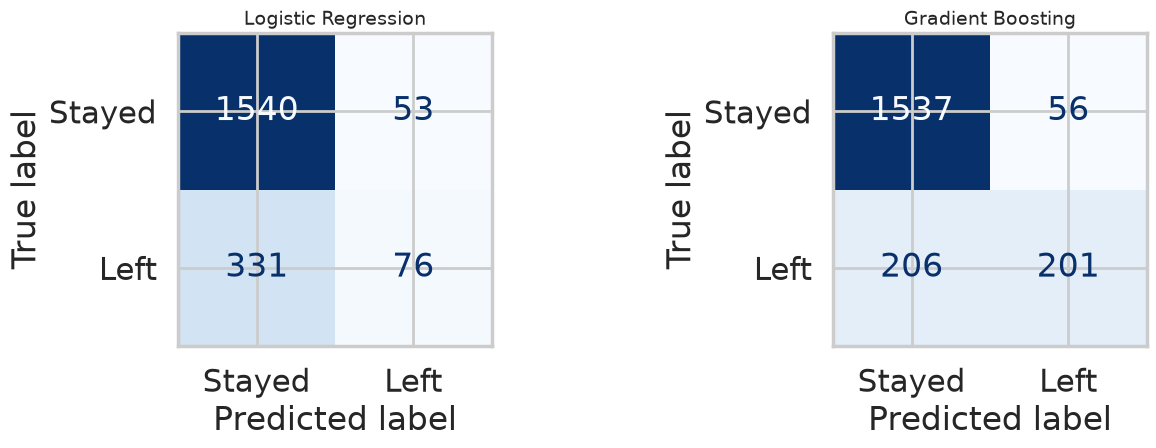

Gradient Boosting: true negatives=1537, false positives=56, false negatives=206, true positives=201


In [32]:
best_name = results_df['F1'].idxmax()
best_model = fitted_models[best_name]
y_pred_best = best_model.predict(X_test)
print(f"Best model by F1: {best_name}\n")
print(classification_report(y_test, y_pred_best, target_names=['Stayed (0)', 'Left (1)']))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ['Logistic Regression', best_name]):
    ConfusionMatrixDisplay.from_predictions(y_test, fitted_models[name].predict(X_test),
                                            display_labels=['Stayed', 'Left'], cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(name, fontsize=14)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_best).ravel()
print(f"{best_name}: true negatives={tn}, false positives={fp}, false negatives={fn}, true positives={tp}")

**My notes on the confusion matrix (Gradient Boosting):** Out of 407 customers in the test set who really left, the model caught **201** (true positives) and missed **206** (false negatives). It wrongly flagged only **56** of the 1593 stayers (false positives). So when the model says "this customer will leave", it is right about 78% of the time (precision 0.782), but with the default threshold it finds only about half of the leavers (recall 0.494).

### Catching more leavers: changing the decision threshold

By default a model says "will leave" when the predicted probability is above 0.5. For the bank, missing a leaver (false negative) is usually more expensive than contacting a customer who would have stayed anyway (false positive). So I check what happens with a lower threshold.

In [33]:
best_proba = best_model.predict_proba(X_test)[:, 1]
threshold_rows = []
for threshold in [0.5, 0.4, 0.3, 0.2]:
    pred = (best_proba >= threshold).astype(int)
    threshold_rows.append({
        'Threshold': threshold,
        'Customers flagged': int(pred.sum()),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
    })
pd.DataFrame(threshold_rows).round(3)

,Threshold,Customers flagged,Precision,Recall,F1
0,0.5,257,0.782,0.494,0.605
1,0.4,314,0.713,0.550,0.621
2,0.3,419,0.628,0.646,0.637
3,0.2,610,0.511,0.767,0.614


**My note:** If I lower the threshold to **0.3**, the model flags 419 customers instead of 257. Recall goes up from 0.494 to 0.646 (it now catches about 65% of the leavers), and precision goes down from 0.782 to 0.628. F1 is even a little higher (0.637 vs 0.605). The right threshold is a business choice: it depends on how much a retention offer costs compared with how much the bank loses when a customer leaves.

## Step 5 – Which features matter most?

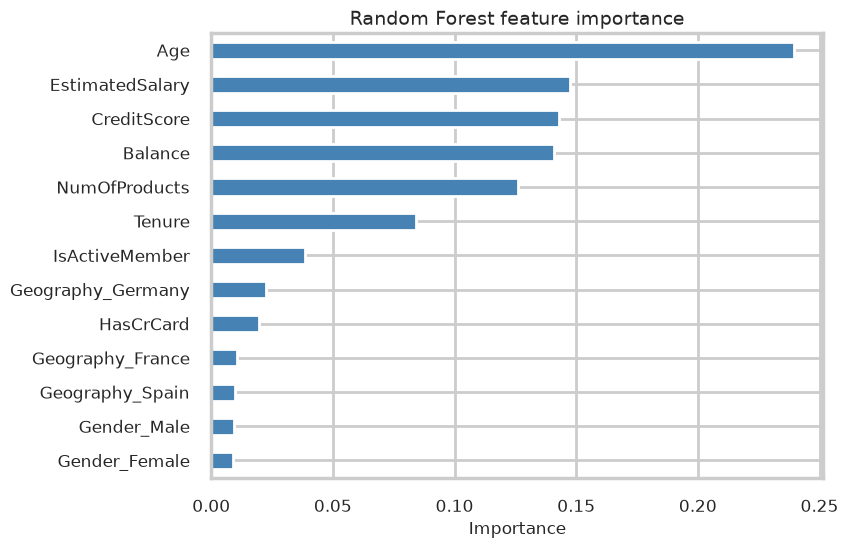

Age                  0.240
EstimatedSalary      0.147
CreditScore          0.143
Balance              0.141
NumOfProducts        0.126
Tenure               0.084
IsActiveMember       0.038
Geography_Germany    0.023
HasCrCard            0.019
Geography_France     0.011
Geography_Spain      0.010
Gender_Male          0.009
Gender_Female        0.009
dtype: float64


In [34]:
rf_model = fitted_models['Random Forest']
feature_names = [n.split('__')[1] for n in rf_model.named_steps['preprocess'].get_feature_names_out()]
importances = pd.Series(rf_model.named_steps['classifier'].feature_importances_, index=feature_names).sort_values()

importances.plot(kind='barh', figsize=(9, 6), color='steelblue', fontsize=12)
plt.title('Random Forest feature importance', fontsize=14)
plt.xlabel('Importance', fontsize=12)
plt.tight_layout()
plt.show()
print(importances.sort_values(ascending=False).round(3))

In [35]:
# Logistic Regression coefficients (on standardised features): sign shows direction
lr_model = fitted_models['Logistic Regression']
lr_names = [n.split('__')[1] for n in lr_model.named_steps['preprocess'].get_feature_names_out()]
coefficients = pd.Series(lr_model.named_steps['classifier'].coef_[0], index=lr_names).sort_values()
print("Logistic Regression coefficients (positive = higher chance to leave):")
print(coefficients.round(3))

# Churn rate by a few categories, to read the effects in plain numbers
for col in ['Geography', 'IsActiveMember', 'NumOfProducts', 'Gender']:
    print(f"\nChurn rate by {col}:")
    print(df.groupby(col)['Exited'].agg(['mean', 'count']).rename(columns={'mean': 'churn rate', 'count': 'customers'}).round(3))

Logistic Regression coefficients (positive = higher chance to leave):
Gender_Male         -0.682
Geography_France    -0.570
Geography_Spain     -0.524
IsActiveMember      -0.516
Gender_Female       -0.158
CreditScore         -0.086
NumOfProducts       -0.070
HasCrCard           -0.032
Tenure              -0.020
EstimatedSalary      0.048
Balance              0.161
Geography_Germany    0.253
Age                  0.739
dtype: float64

Churn rate by Geography:
           churn rate  customers
Geography                       
France          0.162       5014
Germany         0.324       2509
Spain           0.167       2477

Churn rate by IsActiveMember:
                churn rate  customers
IsActiveMember                       
0                    0.269       4849
1                    0.143       5151

Churn rate by NumOfProducts:
               churn rate  customers
NumOfProducts                       
1                   0.277       5084
2                   0.076       4590
3           

**My notes on the features:**
- **Age** is the most important feature in the Random Forest (0.240) and has the largest positive coefficient in Logistic Regression (0.739): older customers leave more. This matches Part 1, where Age had the strongest t-test.
- **NumOfProducts** matters a lot, but not in a straight line: churn is 27.7% with 1 product, only 7.6% with 2, then 82.7% with 3 and 100% with 4 products (only 326 customers in total have 3 or 4).
- **IsActiveMember:** inactive members leave almost twice as often (26.9% vs 14.3%).
- **Geography:** customers in Germany leave about twice as often (32.4%) as in France (16.2%) or Spain (16.7%).
- **Gender:** women leave more often (25.1%) than men (16.5%).
- EstimatedSalary, CreditScore and Balance get high Random Forest importance (0.147, 0.143, 0.141), but I am careful here. This kind of importance favours columns with many different values. In Part 1, salary had no significant difference at all (p ≈ 0.23), and Logistic Regression gives it a coefficient close to 0 (0.048).

## Step 6 – Interpreting the results for business decisions

**My answer: what the bank can do with these results**

1. **Use the model as an early warning list.** I would use Gradient Boosting (F1 0.605, ROC AUC 0.870) to score all customers every month and give the retention team the customers with the highest churn probability. It is much better than guessing: at the 0.5 threshold, 78% of the flagged customers really left.
2. **Choose the threshold based on cost.** Missing a leaver usually costs the bank more than calling a happy customer. So a lower threshold such as 0.3 (catches about 65% of leavers, precision 0.628) is probably better for a cheap action like a phone call or an e-mail offer.
3. **Focus on the high-risk groups the model found:** older customers, inactive members (re-engage them with campaigns, app features or rewards), customers in **Germany** (check service, competition or pricing there), and customers with only 1 product (offer a second product, since 2-product customers churn the least at 7.6%).
4. **Investigate the 3–4 product customers.** 82.7% and 100% of them left. This looks like a problem with those product bundles (for example cost or forced cross-selling), and it is worth checking before selling more products to the same customer.
5. **Next steps to improve the model:** tune the hyperparameters with cross-validation, try class weights to handle the imbalance, and retrain regularly with new data.

**Link to Part 1:** Both parts agree that **Age** is the most helpful single feature for predicting churn, and that salary is not useful. The model adds that activity, number of products and country matter too.